## Statistical Mechanics - Computational Excercise 
**Claude Opus 5.5** was used to generate the both the source code and the analysis code for this assignment.

A log of the prompts and code generated by Claude can be found in **_1_prompt_log.ipynb**. 

The entire source code can be found at this public github repo:
 **https://github.com/blam1o1/computational_excercise_lennard_jones_liquid.git**

### Run the Simulation

In [26]:
# Compile code
import os
os.chdir("/scratch/bl3621/stat_mech/computational_excercise_lennard_jones_liquid")
B = "src/params.cpp src/system.cpp src/force.cpp src/thermostat.cpp src/integrator.cpp src/init.cpp src/observables.cpp src/output.cpp"
!g++ -std=c++17 -O2 -Wall -Wextra -o bin/md src/main.cpp {B} 
# Run simulation
!./bin/md input.txt

# ---- parameters
#   N = 2916, density = 0.02 A^-3, mass = 39.98 amu
#   L = 52.6323 A (derived)
#   sigma = 3.405 A, epsilon/kB = 119.8 K (99.6073 amu A^2/ps^2)
#   rc = 2.5 sigma = 8.5125 A, lambda = 0.1 sigma = 0.3405 A
#   T = 100 K, thermostat = nhc
#   NHC: M = 5, tau = 100 dt = 0.5 ps, nc = 1, nsy = 7
#   dt = 0.005 ps, n_equil = 10000 (50 ps), n_prod = 50000 (250 ps)
#   seed = 42, thermo_every = 100, traj_every = 1000, sample_every = 10
#   g(r): dr = 0.05 A, r_max = L/2 = 26.3162 A; S(q): q = 0.5 ... 15 A^-1, dq = 0.01 A^-1
# ---- run
  equil  step      1000  t =     5.000 ps  T_kin =   96.141 K  <T_kin> =   78.187 K  DeltaE = 1.102e-05
  equil  step      2000  t =    10.000 ps  T_kin =   99.992 K  <T_kin> =   89.061 K  DeltaE = 1.644e-05
  equil  step      3000  t =    15.000 ps  T_kin =   96.780 K  <T_kin> =   92.653 K  DeltaE = 1.848e-05
  equil  step      4000  t =    20.000 ps  T_kin =  100.225 K  <T_kin> =   94.669 K  DeltaE = 1.969e-05
  equil  step      5000  t =    

### Outputs Generated by Code / Analysis of Simulation

In [28]:
import os, re, shutil, subprocess
import numpy as np
import matplotlib.pyplot as plt

RUN_DIR = "/scratch/bl3621/stat_mech/computational_excercise_lennard_jones_liquid"

# ---- Load the run: parameters from input.txt and the thermo logs of both phases
DEFAULTS = {"N": 864, "T": 100.0, "dt": 0.005, "n_equil": 10000, "n_prod": 50000,
            "thermo_every": 100, "sigma": 3.405, "density": 0.02, "output_prefix": ""}

def read_input(path):
    """input.txt -> dict (comments stripped, numbers converted); missing keys take params.h defaults."""
    p = dict(DEFAULTS)
    for line in open(path):
        words = line.split("#")[0].split()
        if len(words) == 2:
            key, value = words
            try:
                value = float(value)
            except ValueError:
                pass
            p[key] = value
    return p

P = read_input(os.path.join(RUN_DIR, "input.txt"))
N, T0, dt, sigma = int(P["N"]), P["T"], P["dt"], P["sigma"]
N_f = 3 * N - 3                          # degrees of freedom (total momentum removed)
t_prod = P["n_equil"] * dt               # production starts here, ps

def out_file(name):
    return os.path.join(RUN_DIR, P["output_prefix"] + name)

# thermo_*.dat columns (see the file headers); energies per particle in units of epsilon
COLS = ["step", "time", "T", "T_avg", "K", "U", "H", "dH_rel", "dE"]
def load_thermo(name):
    d = np.loadtxt(out_file(name))
    return {c: d[:, i] for i, c in enumerate(COLS)}

eq, pr = load_thermo("thermo_equil.dat"), load_thermo("thermo_prod.dat")
run = {c: np.concatenate([eq[c], pr[c]]) for c in COLS}     # whole run, t = 0 ... end

def mark_production(ax, y=0.98):
    """Dashed line where production starts; y = label height as a fraction of the axes."""
    ax.axvline(t_prod, color=INK2, lw=0.8, ls="--")
    ax.annotate("production", (t_prod, y), xycoords=("data", "axes fraction"),
                xytext=(4, 0), textcoords="offset points", va="top", fontsize=9, color=INK2)

print(f"N = {N}, T = {T0:g} K, dt = {dt:g} ps ({dt*1e3:g} fs), equilibration {t_prod:g} ps, "
      f"production {P['n_prod']*dt:g} ps, thermo lines every {int(P['thermo_every'])} steps")

#Plotting parameters
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#a3a29c"                                   # raw / instantaneous data
INK, INK2, RULE = "#0b0b0b", "#52514e", "#e4e3de"  # text, secondary text, grid
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": "#b9b8b3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": RULE, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "lines.linewidth": 1.5, "legend.frameon": False, "legend.fontsize": 9,
})

N = 2916, T = 100 K, dt = 0.005 ps (5 fs), equilibration 50 ps, production 250 ps, thermo lines every 100 steps


##### 1. Trace of conserved energy over the course of the run.

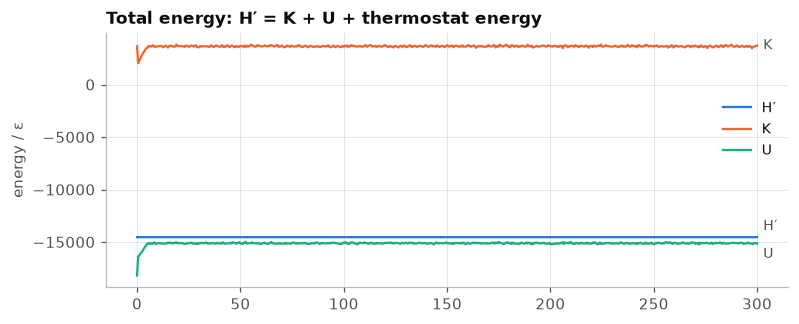

In [38]:
N = 2916                          
scale, unit = N, "ε"                   
fig, (a1) = plt.subplots(1, 1, figsize=(8, 3), sharex=True, gridspec_kw={"hspace": 0.3})
series = [("H′", np.asarray(run["H"]) * scale, BLUE, 7),
          ("K",  np.asarray(run["K"]) * scale, ORANGE, 0),
          ("U",  np.asarray(run["U"]) * scale, AQUA, -7)]
for name, y, c, dy in series:
    a1.plot(run["time"], y, color=c, label=name)
    a1.annotate(name, (run["time"][-1], y[-1]), xytext=(4, dy), textcoords="offset points",
                va="center", color=INK2, fontsize=9)
a1.set_title("Total energy: H′ = K + U + thermostat energy")
a1.set_ylabel(f"energy / {unit}")
a1.legend(loc="center right", bbox_to_anchor=(1.0, 0.62))

##### 2. Cumulative average of the energy conservation measure delta_E over the run.

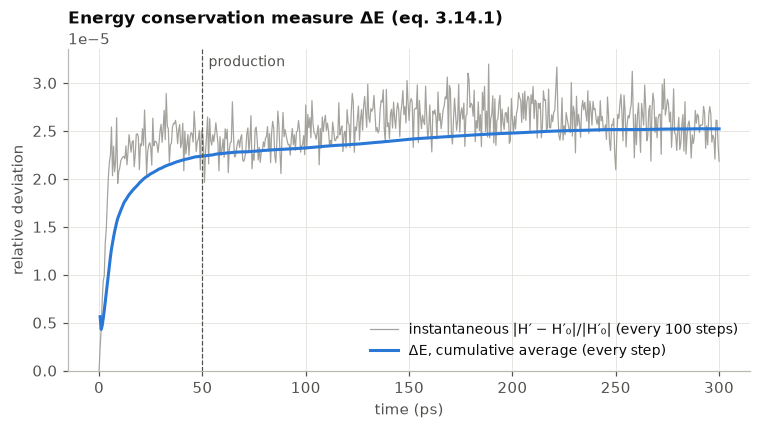

Delta E at the end of equilibration = 2.238e-05
Delta E over the whole run          = 2.522e-05   (book: ~1e-4 is typical, Fig. 3.7)


In [30]:
inst = np.abs(run["dH_rel"])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(run["time"], inst, color=GREY, lw=0.8,
        label=f"instantaneous |H′ − H′₀|/|H′₀| (every {int(P['thermo_every'])} steps)")
ax.plot(run["time"], run["dE"], color=BLUE, lw=2, label="ΔE, cumulative average (every step)")
ax.set_title("Energy conservation measure ΔE (eq. 3.14.1)")
ax.set_xlabel("time (ps)")
ax.set_ylabel("relative deviation")
ax.set_ylim(bottom=0)
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.legend(loc="lower right")
mark_production(ax)
plt.show()
print(f"Delta E at the end of equilibration = {eq['dE'][-1]:.3e}")
print(f"Delta E over the whole run          = {pr['dE'][-1]:.3e}   (book: ~1e-4 is typical, Fig. 3.7)")

##### 3. Instantaneous kinetic energy and cumulative average of the kinetic energy in temperature units.

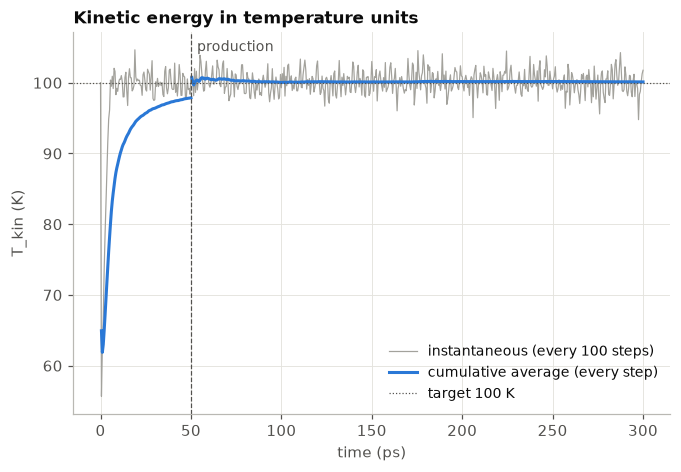

production <T_kin> = 100.117 K (target 100 K)


In [31]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    run["time"], run["T"],
    color=GREY, lw=0.8,
    label=f"instantaneous (every {int(P['thermo_every'])} steps)"
)
ax.plot(
    eq["time"], eq["T_avg"],
    color=BLUE, lw=2,
    label="cumulative average (every step)"
)
ax.plot(
    pr["time"], pr["T_avg"],
    color=BLUE, lw=2
)
ax.axhline(T0, color=INK2, lw=0.8, ls=":", label=f"target {T0:g} K")
ax.set_title("Kinetic energy in temperature units")
ax.set_xlabel("time (ps)")
ax.set_ylabel("T_kin (K)")
ax.legend(loc="lower right")
mark_production(ax)
plt.show()
print(f"production <T_kin> = {pr['T_avg'][-1]:.3f} K (target {T0:g} K)")

##### 4. Final g(r)

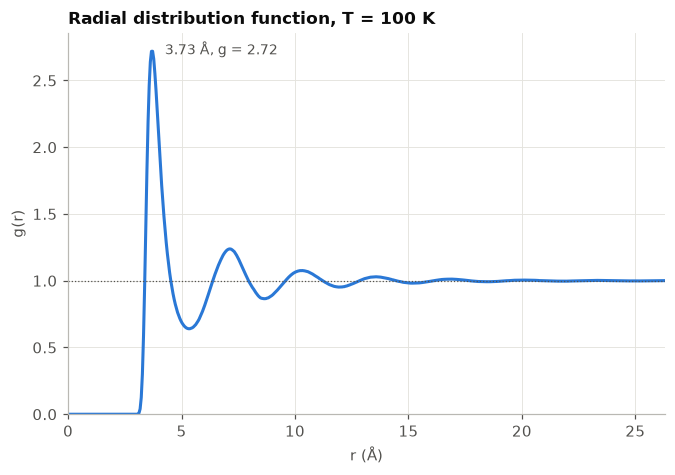

first peak r = 3.725 Å = 1.094 sigma, g = 2.719


In [32]:
r, g, n_r = np.loadtxt(out_file("gr.dat"), unpack=True)
dr = r[1] - r[0]
i_peak = np.argmax(g)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(r, g, color=BLUE, lw=2)
ax.axhline(1, color=INK2, lw=0.8, ls=":")
ax.annotate(
    f"{r[i_peak]:.2f} Å, g = {g[i_peak]:.2f}",
    (r[i_peak], g[i_peak]),
    xytext=(8, -2),
    textcoords="offset points",
    fontsize=9,
    color=INK2
)
ax.set_title(f"Radial distribution function, T = {T0:g} K")
ax.set_xlabel("r (Å)")
ax.set_ylabel("g(r)")
ax.set_xlim(0, r[-1] + dr / 2)
ax.set_ylim(bottom=0)
plt.show()
print(
    f"first peak r = {r[i_peak]:.3f} Å = "
    f"{r[i_peak]/sigma:.3f} sigma, g = {g[i_peak]:.3f}"
)

##### 5. Final S(q)

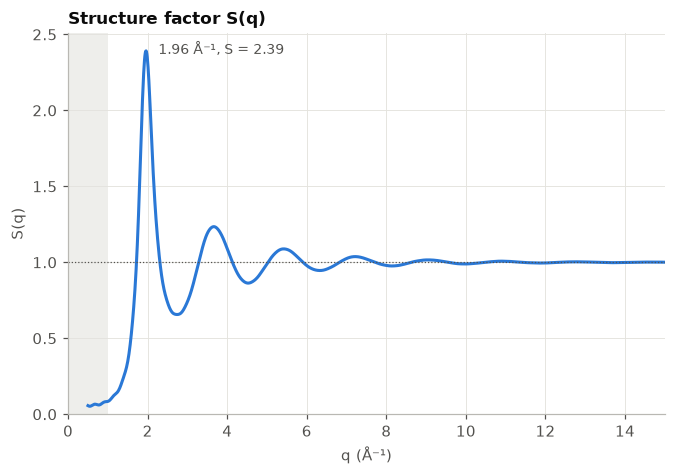

main peak q = 1.960 1/A, S = 2.392;  


In [33]:
q, S = np.loadtxt(out_file("sq.dat"), unpack=True)
k_peak = np.argmax(S)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axvspan(0, 1.0, color=RULE, alpha=0.6, lw=0)
ax.plot(q, S, color=BLUE, lw=2)
ax.axhline(1, color=INK2, lw=0.8, ls=":")
ax.annotate(
    f"{q[k_peak]:.2f} Å⁻¹, S = {S[k_peak]:.2f}",
    (q[k_peak], S[k_peak]),
    xytext=(8, -2),
    textcoords="offset points",
    fontsize=9,
    color=INK2
)
ax.set_title("Structure factor S(q)")
ax.set_xlabel("q (Å⁻¹)")
ax.set_ylabel("S(q)")
ax.set_xlim(0, q[-1])
ax.set_ylim(bottom=0)
plt.show()
print(
    f"main peak q = {q[k_peak]:.3f} 1/A, "
    f"S = {S[k_peak]:.3f};  "
)

### Assesment of Correctness of Final g(r) and S(q)

##### g(r)
The radial distribution plot generated from this simulation is in reasonable agreement with Fig. 4.2 in the Statistical Mechanics textbook. With a sigma value of 3.405 A and an epsilon value of 119.8 K a peak with an g(r) intensity of 2.72 is also observed at r value of 3.73 A, which similarly observed in Fig. 4.2. This peak corresponds to the first coordination shell in the liquid. In Fig 4.2 a second peak with an intensity of 1.25 (g(r)) is observed at a r value of around 7.5 A. We can also observe this peak in our generated plot, which corresponds to the second coordination shell. Furthermore, broad peaks in the g(r) can confirm that the lattice has melted into a liquid. If the lattice had not melted we would see sharp severe peaks rather than softer broader peaks.

##### S(q)
The structure factor plot generated from this simulation also in reasonable agreement with Fig. 4.5 in the Statistical Mechanics textbook. In the reference plot an initial peak of with an S(q) value of around 1.5 is observed at q value of around 2. We can also observe an initial peak at q value of 1.96(A^-1). This first peak corresponds to the liquids dominant density wavelength. 


##### Has the calculation run long enough to generate converged result?

In [37]:
eq, pr = np.loadtxt("thermo_equil.dat"), np.loadtxt("thermo_prod.dat")
t, T, Tcum = pr[:, 1], pr[:, 2], pr[:, 3]
n, h = len(T), len(T) // 2
print("running <T_kin> at 25/50/75/100%:", [round(Tcum[int(f*n) - 1], 3) for f in (.25, .5, .75, 1)])
for name, x in (("T_kin", T),):
    print(f"{name}: halves {x[:h].mean():.4f} vs {x[h:].mean():.4f}")
    for b in (1, 5, 25, 50):                   
        m = n // b; blocks = x[:m*b].reshape(m, b).mean(1)
        print(f"   block {b*0.5:5.1f} ps: mean {x.mean():.4f} +- {blocks.std(ddof=1)/np.sqrt(m):.4f}")
    tb, xb = t.reshape(10, -1).mean(1), x.reshape(10, -1).mean(1)
    p, cov = np.polyfit(tb, xb, 1, cov=True)
    print(f"   trend over production: {p[0]*(t[-1]-t[0]):+.4f} +- {np.sqrt(cov[0, 0])*(t[-1]-t[0]):.4f}")
last = eq[:, 1] > eq[-1, 1] - 10
print(f"last 10 ps of equilibration: <T> = {eq[last, 2].mean():.2f} K")
print(f"std(T) = {T.std():.3f} K, canonical = {100*np.sqrt(2/2589):.3f} K")

running <T_kin> at 25/50/75/100%: [np.float64(100.106), np.float64(100.13), np.float64(100.166), np.float64(100.116)]
T_kin: halves 100.1084 vs 100.1186
   block   0.5 ps: mean 100.1135 +- 0.0702
   block   2.5 ps: mean 100.1135 +- 0.0648
   block  12.5 ps: mean 100.1135 +- 0.0742
   block  25.0 ps: mean 100.1135 +- 0.0905
   trend over production: -0.2170 +- 0.3246
last 10 ps of equilibration: <T> = 99.77 K
std(T) = 1.567 K, canonical = 2.779 K


Yes. We can evaluate if convergence has been reached by looking at <T_kin>, the cumulative average kinetic temperature.

For the cumulative avergage kinetic temperature, while this fluctuates it should equal the target temperature. We can check the convergence by reading the <T_kin> at different progressions of the production run to see if it has settled (code above). We observe that the cumulative <T_kin> remains within 0.2 K of its final value after the first 25% of its run. 

### Unexpected Features Implemented in Code 

1. Box length is a defineable input. In my initial framing of the input.txt parameters I had defined a L parameter corresponding to the size of the simulation cell. I asked Claude to write a function that takes N, L, and a density and generates coordinates to satisfy them. Not exactly a misinterpretation, but the code instead drops the L parameters and generated a cell in accordance to the N of partivles and the desired density.

2. Thermostat time scale. I defined Tau as being greater than or equal to 20 * delta_t. I did not expicitly define a scheme to determine tau. Claude proposed tau = nhc_tau-steps * delta_t wiht a default of 100 * delta_t. The check_params function in params.cpp ensure that tau is not lower than 20 * delta_t.

3. Thermostat mass Q1. I defined Q1 = dNkTtau^2. Instead Claude proposed Q1 = N_f * k * T * tau^2. Where N_f = 3N -3. 

4. The sixth-order Suzuki-Yoshida scheme was defined as the desired integrator for the thermostat. Claude's implementation enables 2nd and 4th order (nhc_nsy = 1 or 3) and enables defining sub-steps per half step in the L_NHC (nhc_nc). It also does not scale velocities at every sub-step, instead it multiples scale factors together and updates the KE and applies the total scaling once at the end of the half step. I believe this implementation is still equivalent.

5. I did not explicitly ask for the simulation to be divided into equilibrium steps and production steps. Claude implemented the input parameters n_equil and n_prod, which chunk the simulation into time steps for allowing the system to reach equilibrium (n_equil) and production steps (n_prod). 

6. Average kinetic energy in temperature units are sampled separetely between equilibrium stage and production stage. This was not explicitly asked for, but was confirmed. This scheme is more intuitive, a canonical average should only include states at equilibrium.